In [1]:
import torch
import torch.nn as nn
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__)
print(device)

2.13.0+cu126
cuda


In [2]:
import torch
import torch.nn as nn
torch.manual_seed(0) # 초기값 재현용
layer = nn.Linear(784, 100) # 입력 784 → 출력 100인 선형 계층
print(layer.weight.shape) # → torch.Size([100, 784]) (출력, 입력) 순서
print(layer.bias.shape) # → torch.Size([100])
n = sum(p.numel() for p in layer.parameters())
print(n) # → 78500 (784×100 + 100)
x = torch.randn(64, 784) # 배치 64개
print(layer(x).shape) # → torch.Size([64, 100])

torch.Size([100, 784])
torch.Size([100])
78500
torch.Size([64, 100])


In [3]:
print(layer.weight[0, :5]) # 0번 뉴런이 가진 가중치 앞 5개
# → tensor([-0.0003, 0.0192, -0.0294, -0.0263, -0.0138], grad_fn=...)
print(layer.bias[0]) # 0번 뉴런의 bias
# → tensor(-0.0354, grad_fn=...)
print(layer.weight.requires_grad) # 학습으로 갱신되는 파라미터라는 표시
# → Tru

tensor([-0.0003,  0.0192, -0.0294, -0.0263, -0.0138], grad_fn=<SliceBackward0>)
tensor(-0.0354, grad_fn=<SelectBackward0>)
True


In [4]:
import torch
z = torch.tensor([-2., -1., 0., 1., 2.])
print(torch.relu(z)) # 음수만 0으로, 양수는 그대로
# → tensor([0., 0., 0., 1., 2.])
print(torch.sigmoid(z)) # 어떤 값이든 0~1 사이로 압축
# → tensor([0.1192, 0.2689, 0.5000, 0.7311, 0.8808])

tensor([0., 0., 0., 1., 2.])
tensor([0.1192, 0.2689, 0.5000, 0.7311, 0.8808])


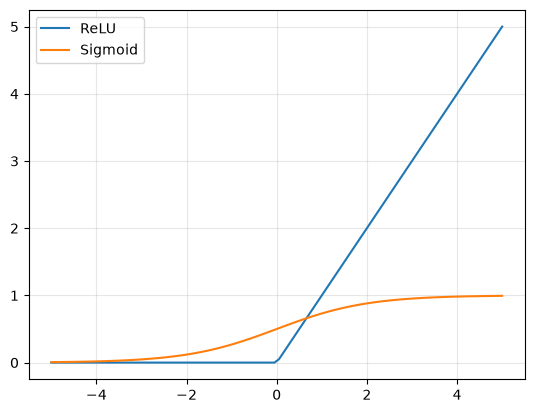

0.0
1.0


In [ ]:
#실습 1. 정답 예시
import torch
import matplotlib.pyplot as plt
z = torch.linspace(-5, 5, 100) 
plt.plot(z, torch.relu(z), label="ReLU") 
plt.plot(z, torch.sigmoid(z), label="Sigmoid")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print(torch.relu(torch.tensor(-3.7)).item()) 
print(torch.sigmoid(torch.tensor(100.)).item()) 

In [8]:
import torch
import torch.nn as nn

class MLP(nn.Module): # 이 클래스 구조는 표준 틀, 복사해서 시작
    def __init__(self):
        super().__init__() # 틀의 고정 문구
        self.fc1 = nn.Linear(784, 100) # 부품 선언: 은닉 계층
        self.act = nn.ReLU() # 부품 선언: 활성화
        self.fc2 = nn.Linear(100, 10) # 부품 선언: 출력 계층
    def forward(self, x): # 데이터가 흐르는 순서를 정의
        return self.fc2(self.act(self.fc1(x)))
    
torch.manual_seed(0)
model = MLP()
print(sum(p.numel() for p in model.parameters())) # → 79510 (78500 + 1010)
print(model(torch.randn(64, 784)).shape) # → torch.Size([64, 10])

79510
torch.Size([64, 10])


In [ ]:
import torch
import torch.nn as nn

class MLP256(nn.Module): # 1. 은닉 뉴런을 100 → 256으로
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.act = nn.ReLU()
        self.fc2 = nn.Linear(256, 10) # 2. 출력 계층의 입력도 함께 256으로
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))
    
model = MLP256()
print(sum(p.numel() for p in model.parameters())) # 3. 파라미터 수 확인
# → 203530 (784×256+256 + 256×10+10)
print(model(torch.randn(8, 784)).shape) # → torch.Size([8, 10])

203530
torch.Size([8, 10])


In [10]:
import torch
import torch.nn as nn
torch.manual_seed(0)
fc1, act, fc2 = nn.Linear(784, 100), nn.ReLU(), nn.Linear(100, 10)
x = torch.randn(64, 784) # 배치 64개가 들어와서
h = fc1(x); print(h.shape) # → torch.Size([64, 100]) (특징 784 → 100)
h = act(h); print(h.shape) # → torch.Size([64, 100]) (활성화는 shape을 안 바꿈)
out = fc2(h); print(out.shape) # → torch.Size([64, 10]) (클래스 수 10)
print(out[0].argmax().item()) # 0번 샘플의 예측 = 10개 logit 중 최댓값 위치
# → (예) 3 (아직 학습 전이라 무작위 수준)

torch.Size([64, 100])
torch.Size([64, 100])
torch.Size([64, 10])
3


In [11]:
import torch
import torch.nn as nn
layer = nn.Linear(784, 100)
print(layer(torch.randn(32, 784)).shape) # 1. 배치 32도 문제없음
# → torch.Size([32, 100])
# 2. CIFAR-10 컬러 이미지 (3, 32, 32)라면 특징 수 = 3×32×32
print(3 * 32 * 32)
# → 3072 (첫 계층은 nn.Linear(3072, ...)로

torch.Size([32, 100])
3072


In [13]:
# 2주차 파이프라인은 그대로 (train_loader, val_loader)
torch.manual_seed(0)
model = MLP().to(device) # 오늘 직접 구현한 그 클래스
opt = torch.optim.SGD(model.parameters(), lr=0.1)
loss_fn = nn.CrossEntropyLoss()
for epoch in range(3):
    for x, y in train_loader: # 2주차 학습 루프 그대로
        x, y = x.view(-1, 784).to(device), y.to(device)
        loss = loss_fn(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    correct = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.view(-1, 784).to(device), y.to(device)
            correct += (model(x).argmax(dim=1) == y).sum().item()
    print(epoch + 1, round(correct / 10000 * 100, 1))
# → (예) 1 89.9
# → (예) 2 93.8
# → (예) 3 94.9 (같은 환경이면 2주차 완성품과 똑같다

NameError: name 'train_loader' is not defined